Found 202 files belonging to 2 classes.
Found 202 files belonging to 2 classes.
Epoch 1/2
7/7 ━━━━━━━━━━━━━━━━━━━━ 72s 11s/step - accuracy: 0.7277 - loss: 1.3959 - val_accuracy: 0.8762 - val_loss: 0.4668
Epoch 2/2
7/7 ━━━━━━━━━━━━━━━━━━━━ 68s 10s/step - accuracy: 0.9406 - loss: 0.2028 - val_accuracy: 0.9356 - val_loss: 0.1820
7/7 ━━━━━━━━━━━━━━━━━━━━ 34s 5s/step - accuracy: 0.9356 - loss: 0.1820
Feature Extraction Accuracy: 0.9356435537338257
Epoch 1/2
7/7 ━━━━━━━━━━━━━━━━━━━━ 83s 12s/step - accuracy: 0.8317 - loss: 0.8168 - val_accuracy: 0.9257 - val_loss: 0.1736
Epoch 2/2
7/7 ━━━━━━━━━━━━━━━━━━━━ 82s 12s/step - accuracy: 0.9406 - loss: 0.1617 - val_accuracy: 0.9406 - val_loss: 0.1557
7/7 ━━━━━━━━━━━━━━━━━━━━ 35s 5s/step - accuracy: 0.9406 - loss: 0.1557
Fine Tuning Accuracy: 0.9405940771102905


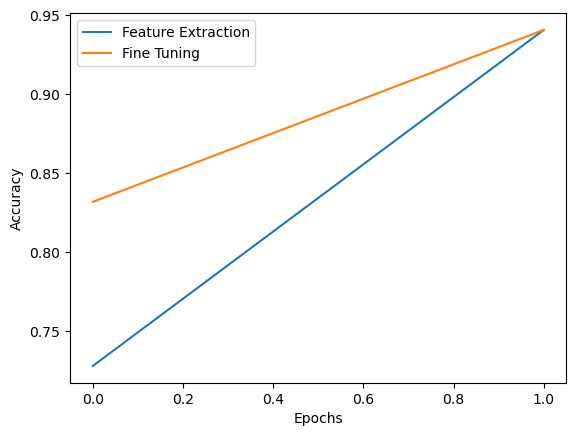

In [3]:
# # Step I : Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# Step II : Load Dataset

train_dir = "cats_and_dogs_filtered/train"
test_dir = "cats_and_dogs_filtered/validation"

# Step III : Load Images
train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224,224),
    batch_size=32,
    label_mode='binary'
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224,224),
    batch_size=32,
    label_mode='binary'
)

# Step IV : Preprocessing
train_data = train_data.map(lambda x,y: (preprocess_input(x),y))
test_data = test_data.map(lambda x,y: (preprocess_input(x),y))

# Step V : Load Pretrained Model
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# Freeze layers
base_model.trainable = False

# Step VI : Build Model
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Step VII : Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Step VIII : Train Model
history = model.fit(
    train_data,
    epochs=2,
    validation_data=test_data
)

# Step IX : Evaluate Model
loss, accuracy = model.evaluate(test_data)
print("Feature Extraction Accuracy:", accuracy)

# Step X : Fine Tuning
base_model.trainable = True

# Freeze all except last 4 layers
for layer in base_model.layers[:-4]:
    layer.trainable = False

# Compile again
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train again
history2 = model.fit(
    train_data,
    epochs=2,
    validation_data=test_data
)

# Step XI : Final Evaluation
loss, accuracy = model.evaluate(test_data)
print("Fine Tuning Accuracy:", accuracy)

# Step XII : Compare Accuracy
plt.plot(history.history['accuracy'], label='Feature Extraction')
plt.plot(history2.history['accuracy'], label='Fine Tuning')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
